<a href="https://colab.research.google.com/github/cmburban/MAT-422/blob/main/MAT422_Section_3_3_Optimization_Gradient_Descent.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MAT 422 - Section 3.3: Optimization and Gradient Descent

**Topics:** Necessary and sufficient conditions of local minimizers, Convexity and global minimizers, Gradient descent

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=5, suppress=True)

## 3.3.1 Necessary and Sufficient Conditions of Local Minimizers

A local minimum is a point where a function has a value that is less than or equal to nearby values. For a differentiable function, a necessary condition for an interior local minimum is that its derivative equals zero. However, a derivative of zero does not always mean that a point is a minimum.

For a twice-differentiable function, a positive second derivative at a stationary point is a sufficient condition for a strict local minimum.

I will use the function f(x) = (x - 3)² + 2 to demonstrate these conditions.

In [2]:
def f(x):
    return (x - 3)**2 + 2

def f_prime(x):
    return 2 * (x - 3)

def f_double_prime(x):
    return 2

x_min = 3

print("Function value at x = 3:", f(x_min))
print("First derivative at x = 3:", f_prime(x_min))
print("Second derivative at x = 3:", f_double_prime(x_min))

print("\nFirst derivative equals zero:", np.isclose(f_prime(x_min), 0))
print("Second derivative is positive:", f_double_prime(x_min) > 0)

Function value at x = 3: 2
First derivative at x = 3: 0
Second derivative at x = 3: 2

First derivative equals zero: True
Second derivative is positive: True


The first derivative equals zero at x = 3, which satisfies the necessary condition for an interior local minimum. The second derivative is positive, so the function curves upward at this point. Together, these results confirm that x = 3 is a strict local minimum, with a function value of 2.

### Visualizing the Local Minimum

A graph helps show how the function behaves around its minimum. I will plot the function and mark the point where the minimum occurs.

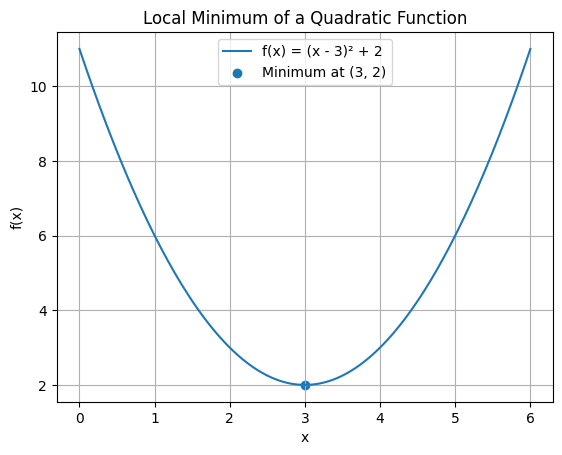

In [3]:
x_values = np.linspace(0, 6, 200)
y_values = f(x_values)

plt.plot(x_values, y_values, label="f(x) = (x - 3)² + 2")
plt.scatter([x_min], [f(x_min)], label="Minimum at (3, 2)")

plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Local Minimum of a Quadratic Function")
plt.legend()
plt.grid(True)

plt.show()

The graph shows a U-shaped curve with its lowest point at (3, 2). The function values increase as x moves away from 3 in either direction. This visually confirms that x = 3 is the minimum of this function.

## 3.3.2 Convexity and Global Minimizers

A function is convex when the line segment between any two points on its graph lies on or above the graph. For a twice-differentiable function of one variable, a nonnegative second derivative throughout an interval is a sufficient condition for convexity on that interval.

A global minimum is a point where the function has its lowest value across its entire domain. For a convex function, a local minimum is also a global minimum.

I will use the function f(x) = (x + 2)² + 1 to demonstrate convexity and find its global minimum.

In [4]:
def g(x):
    return (x + 2)**2 + 1

def g_prime(x):
    return 2 * (x + 2)

def g_double_prime(x):
    return 2

x_min = -2

print("Function value at x = -2:", g(x_min))
print("First derivative at x = -2:", g_prime(x_min))
print("Second derivative:", g_double_prime(x_min))
print("Second derivative is nonnegative:", g_double_prime(x_min) >= 0)

# Compare the minimum with values at other points
test_points = np.array([-5, -3, -2, -1, 1])
test_values = g(test_points)

print("\nTest points:", test_points)
print("Function values:", test_values)
print("Is the value at x = -2 the smallest?",
      g(x_min) <= np.min(test_values))

Function value at x = -2: 1
First derivative at x = -2: 0
Second derivative: 2
Second derivative is nonnegative: True

Test points: [-5 -3 -2 -1  1]
Function values: [10  2  1  2 10]
Is the value at x = -2 the smallest? True


The second derivative is positive everywhere, which confirms that the function is strictly convex. The first derivative equals zero at x = -2, and the function value there is lower than at the other test points. Because this function is convex, its minimum at x = -2 is also its global minimum.

### Visualizing Convexity and the Global Minimum

The graph will show the shape of the function and mark its lowest point. Since the function is a convex quadratic, the graph should have a U shape.

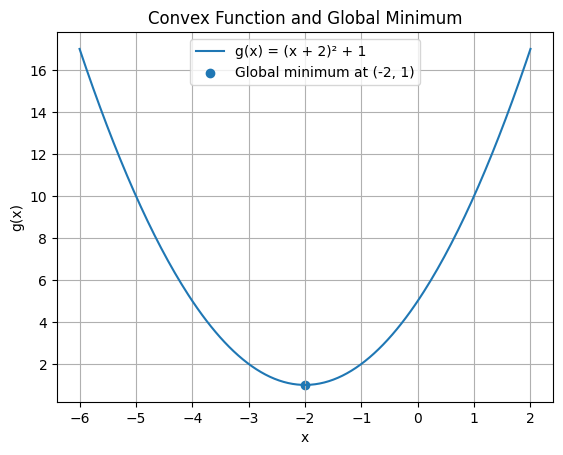

In [5]:
x_values = np.linspace(-6, 2, 200)
y_values = g(x_values)

plt.plot(x_values, y_values, label="g(x) = (x + 2)² + 1")
plt.scatter([x_min], [g(x_min)], label="Global minimum at (-2, 1)")

plt.xlabel("x")
plt.ylabel("g(x)")
plt.title("Convex Function and Global Minimum")
plt.legend()
plt.grid(True)

plt.show()

The graph shows a U-shaped curve with its lowest point at (-2, 1). The function increases as x moves away from -2 in either direction. This supports the numerical results and illustrates how convexity helps identify a global minimum.

## 3.3.3 Gradient Descent

Gradient descent is an optimization method that repeatedly updates a value in the direction opposite the gradient. The goal is to find a value that minimizes a function.

The update rule is:

\[
x_{\text{new}} = x_{\text{old}} - \alpha f'(x_{\text{old}})
\]

where \(\alpha\) is the learning rate, which controls the size of each step.

I will use gradient descent to minimize the function f(x) = (x - 4)² + 2. The minimum occurs at x = 4, where the function value is 2. I will start at x = -2 and see whether gradient descent approaches this minimum.

In [6]:
def f(x):
    return (x - 4)**2 + 2

def f_prime(x):
    return 2 * (x - 4)

# Gradient descent settings
x = -2.0
learning_rate = 0.1
iterations = 50

# Store the optimization history
x_history = [x]
f_history = [f(x)]

for i in range(iterations):
    x = x - learning_rate * f_prime(x)

    x_history.append(x)
    f_history.append(f(x))

print("Starting x:", x_history[0])
print("Final x:", x_history[-1])
print("Final function value:", f_history[-1])
print("Known minimum x: 4")
print("Known minimum function value: 2")

Starting x: -2.0
Final x: 3.999914365138438
Final function value: 2.0000000073333295
Known minimum x: 4
Known minimum function value: 2


The algorithm starts at x = -2 and repeatedly updates x using the derivative of the function. The final value should be close to x = 4, where the function reaches its minimum value of 2. This shows how gradient descent can approach a minimum without calculating the answer directly.

### Visualizing Gradient Descent

I will plot the function and show the sequence of points visited during gradient descent. This helps demonstrate how each update moves toward the minimum.

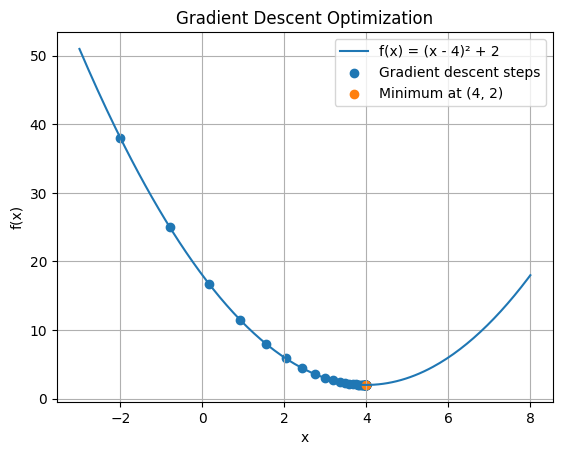

In [7]:
x_values = np.linspace(-3, 8, 200)
y_values = f(x_values)

plt.plot(x_values, y_values, label="f(x) = (x - 4)² + 2")

plt.scatter(
    x_history,
    f_history,
    label="Gradient descent steps"
)

plt.scatter(
    [4],
    [2],
    label="Minimum at (4, 2)"
)

plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Gradient Descent Optimization")
plt.legend()
plt.grid(True)

plt.show()

### Tracking the Function Value

The function value should decrease as gradient descent approaches the minimum. Plotting the function value after each iteration lets me check whether the algorithm is making progress.

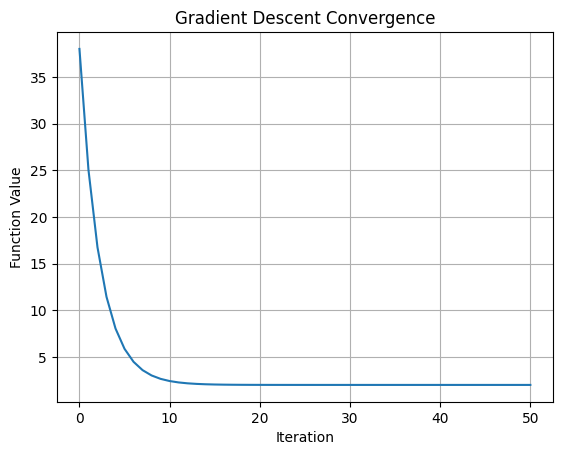

In [8]:
plt.plot(range(len(f_history)), f_history)

plt.xlabel("Iteration")
plt.ylabel("Function Value")
plt.title("Gradient Descent Convergence")
plt.grid(True)

plt.show()

The graph shows the function value decreasing as the iterations progress. The values approach the minimum function value of 2, showing that gradient descent is converging toward the solution for this example.

## End of Notebook Reflection

In this notebook, I learned how derivatives can help identify local minima. In the first example, the first derivative was zero and the second derivative was positive, which confirmed a strict local minimum.
I also learned how convexity helps determine whether a minimum is global. The quadratic example was convex because its second derivative was positive, so its minimum was the lowest point over the entire domain.
Finally, I learned how gradient descent can approach a minimum by repeatedly moving in the direction opposite the derivative. Starting from x = -2, the algorithm moved toward x = 4, and the function value approached 2. The plots helped me see how the method made progress over repeated iterations.
Overall, these examples helped me understand how derivatives, convexity, and gradient descent are used to solve optimization problems.

## References

[Mathematical Methods in Data Science - Elsevier (2023)](https://doi.org/10.1016/B978-0-44-318679-0.00007-7)

[Numpy - Singular Value Decomposition](https://numpy.org/doc/stable/reference/generated/numpy.linalg.svd.html)

[Matplotlib](https://matplotlib.org/stable/)

[OpenAI - ChatGPT (2026)](https://chatgpt.com)

## Submission Checklist

- I explained each concept in words before or after the code. [DONE]
- I verified important claims numerically or visually. [DONE]
- I changed or extended at least one example so the notebook reflects my own work. [DONE]
- I ran the notebook from top to bottom without errors. [DONE]
- I saved the notebook from Google Colab directly to GitHub, following the course instructions. [DONE]
